# 08. Unified Business Intelligence & Procurement Synthesis
**Phase 2: Exploratory Data Analysis & Decision Intelligence**  
**Team:** Team Sabuj Sangha (Abhranil Pal & Arka Dyuti Bose)

Cross-domain synthesis combining customer demand, supplier offerings, inventory availability, and cancellation buffers to formulate actionable procurement rules.


In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))

import pandas as pd
from IPython.display import Image, display
from eda.data_loader import load_all_datasets
from eda.kpi_calculations import compute_hotel_kpis, compute_supplier_kpis, compute_inventory_kpis, compute_flight_price_kpis
from eda.relationship_analysis import analyze_demand_vs_supply
from eda.business_insights import generate_executive_business_insights
from eda.visualization import plot_cross_domain_demand_vs_supply_gap


## 1. Cross-Domain Demand vs Supply Alignment


In [2]:
datasets = load_all_datasets(prefer_parquet=True)
demand_supply_df = analyze_demand_vs_supply(
    datasets["customer_search_events"],
    datasets["inventory_availability"],
    datasets["supplier_offers"],
)
demand_supply_df.head(10)


,destination_id,search_volume,clicks,bookings,avg_searched_price_inr,inventory_items,total_capacity,booked_units,available_units,supplier_offers_count,avg_purchase_cost_inr,avg_supplier_selling_inr,avg_margin_pct,demand_to_supply_ratio,procurement_priority
0,DEST001,686,372,118,15657.357303,125,17719,13866,3853,501,6083.259681,7862.192495,22.401297,0.18,Low Demand - Over-Supplied (Hold/Discount)
1,DEST005,638,338,139,10849.191082,135,21839,16261,5578,489,7360.593926,9487.022924,22.222045,0.11,Low Demand - Over-Supplied (Hold/Discount)
2,DEST006,560,303,120,10055.121089,121,18990,15168,3822,494,6841.248360,8873.495000,22.642530,0.15,Low Demand - Over-Supplied (Hold/Discount)
3,DEST009,543,287,107,53389.926390,109,16016,13104,2912,492,19199.816098,24868.798415,22.629715,0.19,Low Demand - Over-Supplied (Hold/Discount)
4,DEST007,530,279,108,9759.167019,133,21871,17274,4597,507,6795.058225,8793.735878,22.589231,0.12,Low Demand - Over-Supplied (Hold/Discount)
5,DEST002,458,252,87,14426.839432,123,19981,15642,4339,519,5549.314355,7190.509441,22.577938,0.11,Low Demand - Over-Supplied (Hold/Discount)
6,DEST010,418,214,72,39792.290096,126,21144,16120,5024,495,14115.025556,18237.388889,22.419576,0.08,Low Demand - Over-Supplied (Hold/Discount)
7,DEST003,415,234,87,16177.922578,124,22145,17228,4917,497,5840.188089,7558.675312,22.507103,0.08,Low Demand - Over-Supplied (Hold/Discount)
8,DEST004,393,214,74,15356.184860,143,21587,17323,4264,516,6311.622074,8198.362946,22.786492,0.09,Low Demand - Over-Supplied (Hold/Discount)
9,DEST008,359,212,100,19065.078440,111,16106,12804,3302,490,7765.810755,10047.040163,22.566776,0.11,Low Demand - Over-Supplied (Hold/Discount)


## 2. Demand vs Supply Gap Visualization


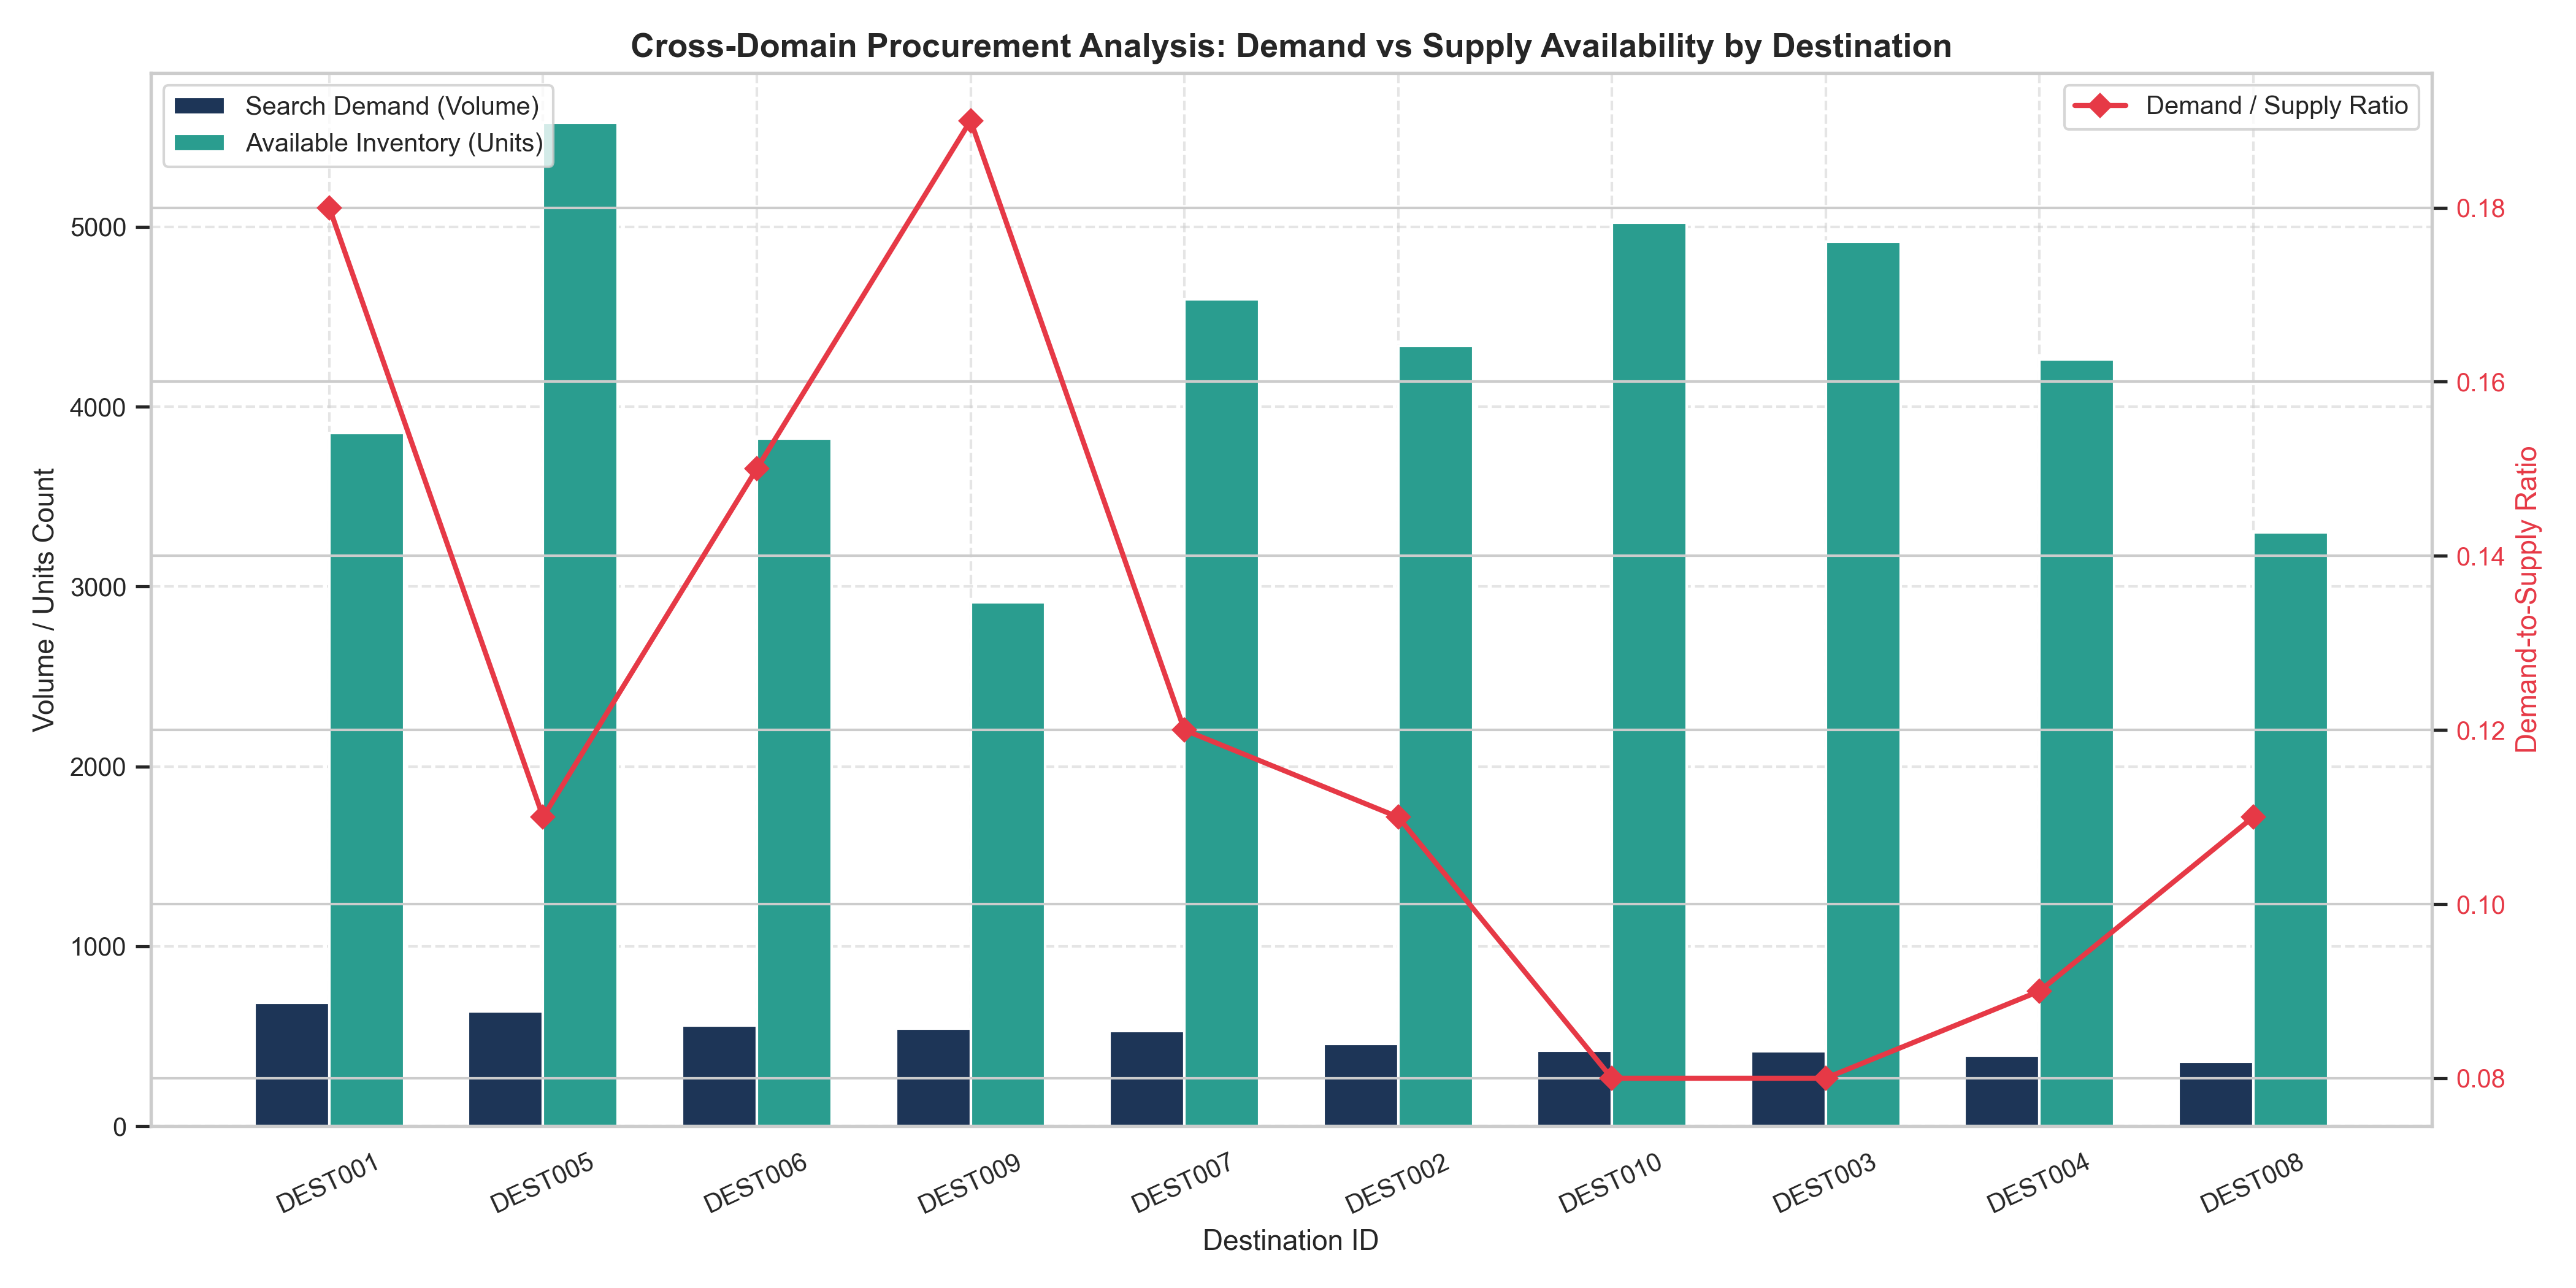

In [3]:
fig12_path = plot_cross_domain_demand_vs_supply_gap(demand_supply_df)
display(Image(filename=str(fig12_path)))


## 3. Executive Procurement Intelligence & Rules


In [4]:
hotel_kpis = compute_hotel_kpis(datasets["hotel_bookings"])
supplier_kpis = compute_supplier_kpis(datasets["supplier_offers"])
inv_kpis = compute_inventory_kpis(datasets["inventory_availability"])
price_kpis = compute_flight_price_kpis(datasets["flight_prices"])

insights = generate_executive_business_insights(
    demand_supply_df, supplier_kpis, hotel_kpis, price_kpis, inv_kpis
)
print("Top Procurement Priority Destinations:", insights["top_procurement_destinations"])
print("Over-Supplied Risk Destinations:", insights["over_supplied_destinations"])
print("Recommended Overbooking Buffer:", f"{insights['cancellation_and_overbooking']['recommended_overbooking_buffer_pct']}%")
print("Supplier Strategy:", insights["supplier_intelligence"]["recommended_supplier_strategy"])


Top Procurement Priority Destinations: []
Over-Supplied Risk Destinations: ['DEST010', 'DEST003', 'DEST004', 'DEST005', 'DEST008']
Recommended Overbooking Buffer: 14.8%
Supplier Strategy: Prioritize procurement with top-margin suppliers who offer refundable contracts. Implement automated price gating to block negative margin inventory offers.
